# Assignment 4: Bills Actions

**Sally Choi**  

**DATASCI 530**

## Introduction
This report examines actions taken on proposed legislation during the 116th United States Congress. The dataset includes descriptions of events such as committee reviews, floor actions, and proposed amendments. Each row records one action associated with a bill, so the same bill may appear several times as it moves through the legislative process (different actions).
The analysis begins with some basic descriptives of the data. It then examines House floor actions involving Senate bills and Senate amendments proposed on the floor. Using regular expressions(finding text patterns)the analysis extracts  senator names and explores how frequently they appear and which senators are mentioned together. 

#### **Key Findings:**

After removing 49 identical records, the dataset contains 3,254 action
records associated with 1,494 distinct legislative measures.
The selected Senate amendment actions involve 131 measures, most
mentioning two distinct senators; McConnell has the most different
second-mentioned senators under the first-two-names approach.The additional analysis finds slightly longer purpose descriptions for
other amendments mentioning two senators, while substitute descriptions
remain similarly short because they use a repeated phrase.

In [3]:
# Import libraries

import pandas as pd
import matplotlib.pyplot as plt

### Data load/processing

In [4]:
# load data
bills_actions = pd.read_csv("bills_actions.csv")

# check length, columns and types
# print(bills_actions.dtypes) 
# print(len(bills_actions))
print(f"Total number of rows(bill actions): {len(bills_actions)}")

Total number of rows(bill actions): 3303


In [13]:
# check for and remove duplicates
# count duplicates
duplicate_count = bills_actions.duplicated().sum()
# print(duplicate_count)

# show duplicate rows next to each other for inspection
duplicates = bills_actions.loc[bills_actions.duplicated(keep=False)]
# display(duplicates.sort_values(by=bills_actions.columns.tolist()))

# keep one copy of each unique row and drop all 49 duplicates
bills_actions = bills_actions.drop_duplicates().copy()

print(f"Removed {duplicate_count} duplicate rows (extra copies of rows that match across all columns)")
print(f"Total number of rows after removing duplicates: {len(bills_actions)}")

# check for missing data
bills_actions.isna().sum()
print("No missing data was found in the dataset")

Removed 49 duplicate rows (extra copies of rows that match across all columns)
Total number of rows after removing duplicates: 3254
No missing data was found in the dataset


#### Brief data cleaning process
- I removed rows that were identical across all columns(duplicates) and just kept one copy of each unique row so that repeated records would not be counted as separate bill actions. I retained different actions associated with the same bill.
- No is no missing data in the dataset.


## Basic descriptive stats

#### How many distinct “bill” identifiers are there? What proportion of rows belongs to each category? What proportion belongs to different “main_action”.

**Process**

The first part begins with reporting the number of distinct bill identifiers, the distribution of categories and main actions.

I defined bill identifers as the unique combination of Congress, bill type, and bill number. Counting bill numbers alone could combine different bills that share the same number. 

I got the proportions in percentages for each category and main action across the all the bill actions.

In [22]:
# distinguish bill identifiers by Congress, type, and number
with_bill_type = bills_actions[
    ["Congress", "bill_type", "bill_number"]].drop_duplicates()

# identifiers that ignore bill type
without_bill_type = bills_actions[["Congress", "bill_number"]].drop_duplicates()

print("Total number of action records:", len(bills_actions))
print("Distinct bill identifier with Congress, bill type, and bill number:", len(with_bill_type))
print("Distinct bill identifier with only Congress and bill number:", len(without_bill_type))
print("Chose to include the bill type measure to identify distinct bill identifiers. " \
"Therefore, there are 1494 unique identifiers.")

Total number of action records: 3303
Distinct bill identifier with Congress, bill type, and bill number: 1494
Distinct bill identifier with only Congress and bill number: 1331
Chose to include the bill type measure to identify distinct bill identifiers. Therefore, there are 1494 unique identifiers.


#### Defining a bill identifier
- Looking at the DataViewer, I found 8 distinct bill types. About
**67% of rows** have the type "hr" (House bills), and about **20%**
have the type "s" (Senate bills). The other types represent different
kinds of resolutions.
- Different bill types can share the same number. For example, H.R. 1
and S. 1 are different bills, even though both have bill number 1.
If I use only Congress and bill number, they are counted together.
- Using Congress and bill number gives **1,331 unique identifiers**.
Including bill type increases the count to **1,494** because it keeps
these different measures separate.
- I used Congress, bill type, and bill number to identify each distinct
measure. This count includes both bills and resolutions in the dataset, so repeated action records for the same measure are counted only once.

In [25]:
# category percentages
category_percent = (bills_actions["category"].value_counts() / len(bills_actions) * 100)

category_percent.round(1).to_frame(name="Percent of bill actions(rows)")

,Percent of bill actions(rows)
category,
amendment,45.9
house bill,27.3
senate bill,15.8
house resolution,7.2
senate resolution,1.8
house joint resolution,0.7
house concurrent resolution,0.6
senate concurrent resolution,0.4
senate joint resolution,0.2


In [27]:
# main action percentages
count_unique_actions = bills_actions["main_action"].nunique()
# bills_actions["main_action"].unique()
print(f"There are {count_unique_actions} unique main actions")

action_percent = (bills_actions["main_action"].value_counts() / len(bills_actions) * 100)
action_percent.round(1).to_frame(name="Percent of bill actions(rows)")

There are 13 unique main actions


,Percent of bill actions(rows)
main_action,
house floor actions,31.3
house amendment offered,25.4
senate committee/subcommittee actions,13.3
other house amendment actions,11.2
senate amendment proposed (on the floor),8.8
house committee/subcommittee actions,6.3
reported to senate,1.1
senate committee report filed after reporting,1.0
other senate amendment actions,0.6


#### Findings
The dataset contains **3,254 rows** (after removing for duplicates) and **1,494 distinct bills**.

For the categories for each bill action, amendments account for the largest share of rows (**45.9%**), followed
by House bills (**27.3%**) and Senate bills (**15.8%**).

The most common main actions are House floor actions (**31.3%**)
and House amendments offered (**25.4%**).

## House floor actions in Senate bills category
I selected rows where the category is “senate bill” and the main action
is “house floor actions.” This focuses on actions taken in the House
on Senate bills. 

#### What proportion of these actions were suspended? What proportion of these actions were suspended as amended?
**Process**

I searched for “suspend” to identify suspension
motions. Then, I checked which suspension motions also contain “amended.”
Both percentages use all House floor actions in this subset as the
denominator. Suspension motions as amended are included in the total
suspension-motion count.

note: these descriptions record motions to suspend the rules and pass a bill, but 
they do not necessarily establish that the motions passed.

In [99]:
# subset House floor actions in Senate bills
house_floor = bills_actions.query(
    "category == 'senate bill' and main_action == 'house floor actions'").copy()

print("Number of House floor actions in Senate bills:", len(house_floor))

Number of House floor actions in Senate bills: 116


In [100]:
# Identify suspension motions and mentions of "as amended."
suspended = house_floor["action"].str.contains("suspend")
amended = house_floor["action"].str.contains("amend")

# Count motions that meet both conditions.
suspended_amended = suspended & amended

suspension_results = pd.DataFrame({
    "Action": ["Suspended action", "Suspended action as amended"],
    "Count": [suspended.sum(), suspended_amended.sum()],
    "Percent of actions": [
        suspended.mean() * 100,
        suspended_amended.mean() * 100]
        })

suspension_results.style.format({"Percent of actions": "{:.1f}"}).hide(axis="index")

Action,Count,Percent of actions
Suspended action,80,69.0
Suspended action as amended,18,15.5


### Extracting names and counting bills
#### What is the distribution of total bills proposed per person?
**Process**

I used regular expressions to extract names following Mr., Ms., or Mrs.
The pattern captures the text between the title and either “moved” or
“asked” words in the action description. This keeps names with multiple word names, such as Jackson Lee,
together.

I checked whether any actions were missing an extracted name. I then
created a dataset counting 'distinct' bills mentioning each person. I counted the number of distinct bills per person as one bill can have multiple action records mentioning the same person. So, repeated actions for the same bill and person count only once.

Bill number is sufficient to get the distinct bills in this subset since all records are Senate
bills from the same Congress. These counts show bills mentioning a person
in House floor actions.

In [103]:
# creat pattern to extract the name after the title and before "moved" or "asked"
pattern = r"(?:Mr|Ms|Mrs)\. (.*?) (?:moved|asked)"

house_floor["person"] = (house_floor["action"].str.findall(pattern).str[0])

# check if pattern missed names
print("Actions without an extracted name:", house_floor["person"].isna().sum())

Actions without an extracted name: 0


In [110]:
# count distinct bills mentioning each person
person_bills = (
    house_floor.groupby("person")
    .agg(total_bills=("bill_number", "nunique"))
    .reset_index()
    .sort_values("total_bills", ascending=False))

# display(person_bills)

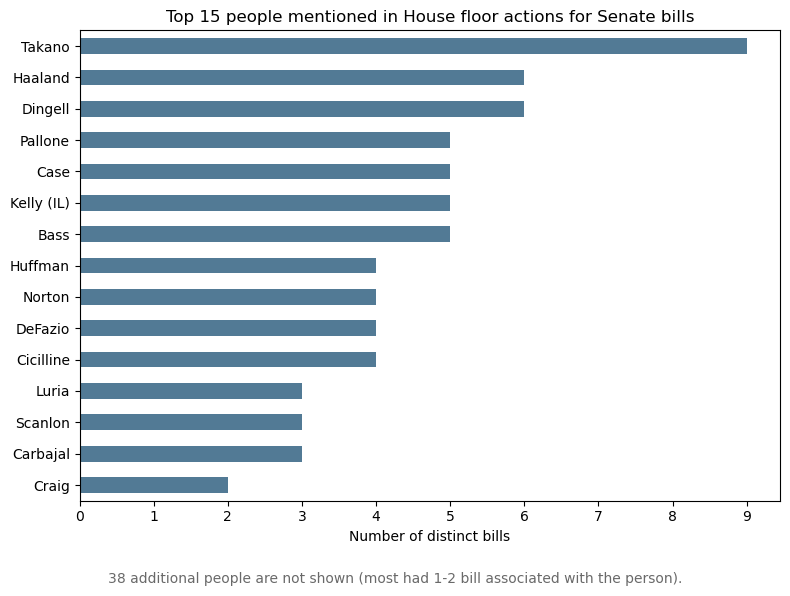

In [94]:
# select the top 15 for graph
top_15 = person_bills.sort_values(
    "total_bills", ascending=False).head(15)

remaining = len(person_bills) - len(top_15)

top_15.sort_values("total_bills").plot.barh(
    x="person",
    y="total_bills",
    color="#527A95",
    figsize=(8, 6),
    legend=False)

plt.title("Top 15 people mentioned in House floor actions for Senate bills")
plt.xlabel("Number of distinct bills")
plt.ylabel("")
plt.xticks(range(0, int(top_15["total_bills"].max()) + 1))

# Add a note below the graph.
plt.figtext(
    0.5, 0.02,
    f"{remaining} additional people are not shown (most had 1-2 bills associated with the person).",
    ha="center", fontsize=10, color="dimgray")

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

### Findings
There are **116 House floor actions** associated with Senate bills.
Of these, **80 (69%)** record motions to suspend the rules, including
**18 (15.5% of all actions)** to pass the bill as amended.

All the actions for this subset mention **53 individuals**. Takano appears for the most distinct
bills (9), followed by Haaland and Dingell (6 each). Most people
appear for only one or two bills, suggesting that a smaller group appears
repeatedly while many others appear less often. The graph shows the top
15 people, with 38 additional people not displayed.

## Senators mentioned in Senate amendments proposed

#### What is the distribution of the number of senators per bill?
**Process**

I selected actions marked “senate amendment proposed (on the floor)”
and used regular expressions searches to extract for names following “Senator.” It allows multiple
words beginning with capital letters so that names with two words (such as Van Hollen) stay together.

I grouped the records by Congress, bill type, and bill number to create
one row per bill. For each bill, I counted distinct senators across its
selected actions, so repeated mentions of the same senator count once. Senator 1 and Senator 2 are the first two distinct senators encountered
in the dataset's existing order.

In [6]:
# select senate amendments proposed on the floor
senate_amendments = bills_actions.query("main_action == 'senate amendment proposed (on the floor)'").copy()

# extract senator names (including numtiple word names)
pattern = r"Senator ([A-Z][a-zA-Z'-]*(?: [A-Z][a-zA-Z'-]*)*)"

senate_amendments["names"] = (
    senate_amendments["action"].str.findall(pattern))

print("Number of amendment actions:", len(senate_amendments))

Number of amendment actions: 286


In [10]:
# combine the name lists from all selected actions for each bill
senator_dataset = (
    senate_amendments.groupby(["Congress", "bill_type", "bill_number"])
    .agg(names=("names", "sum"))
    .reset_index())

# remove repeated names while keeping their first appearance
unique_names = []

for names in senator_dataset["names"]:
    unique_names.append(list(pd.unique(pd.Series(names))))

senator_dataset["names"] = unique_names

# count distinct senators and save first two names
senator_dataset["Number of senators"] = senator_dataset["names"].str.len()
senator_dataset["Senator 1"] = senator_dataset["names"].str[0]
senator_dataset["Senator 2"] = senator_dataset["names"].str[1]

print("Number of distinct bills:", len(senator_dataset))
print("Bills without an extracted senator:",
      (senator_dataset["Number of senators"] == 0).sum())

senator_dataset[
    ["Congress", "bill_type", "bill_number",
     "Number of senators", "Senator 1", "Senator 2"]
     ].head(10).style.hide(axis="index")

Number of distinct bills: 131
Bills without an extracted senator: 0


Congress,bill_type,bill_number,Number of senators,Senator 1,Senator 2
116,hjres,28,2,McConnell,Shelby
116,hjres,31,2,McConnell,Shelby
116,hr,221,2,Moran,Rubio
116,hr,251,2,McConnell,Johnson
116,hr,266,1,McConnell,nan
116,hr,268,3,McConnell,Shelby
116,hr,550,2,McConnell,Murkowski
116,hr,748,2,Sasse,McConnell
116,hr,886,2,Moran,McSally
116,hr,925,2,McConnell,Barrasso


In [11]:
# count bills with each number of distinct senators
distribution = (
    senator_dataset["Number of senators"].value_counts().sort_index())

distribution.rename_axis("Distinct senators per bill").to_frame(
    name="Number of bills"
).style.set_caption("Distribution of senators mentioned per bill")

,Number of bills
Distinct senators per bill,
1,21
2,99
3,4
4,3
5,1
7,1
30,1
38,1


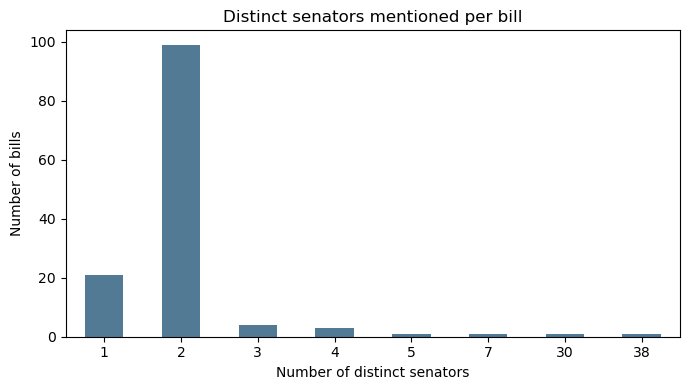

In [12]:
# graph
distribution.plot.bar(color="#527A95", figsize=(7, 4), rot=0)

plt.title("Distinct senators mentioned per bill")
plt.xlabel("Number of distinct senators")
plt.ylabel("Number of bills")
plt.tight_layout()
plt.show()

#### How many different people appear as Senator 2 for each Senator 1?

For each Senator 1, I counted the different names appearing as Senator 2
across bills. Repeated second senators count only once, and missing
second names do not count as partners for coauthoring a bill.

For bills mentioning more than two senators, this calculation uses only
the first two distinct names, as instructed in the guidelines. It therefore does not capture
every possible relationship among the senators mentioned on those bills.

In [18]:
# Count different Senator 2 names associated with each Senator 1.
coauthors = (
    senator_dataset.groupby("Senator 1")
    .agg(partners=("Senator 2", "nunique"))
    .reset_index()
    .sort_values("partners", ascending=False))

#coauthors.style.hide(axis="index").set_caption(
# "Distinct second senators associated with each first senator")

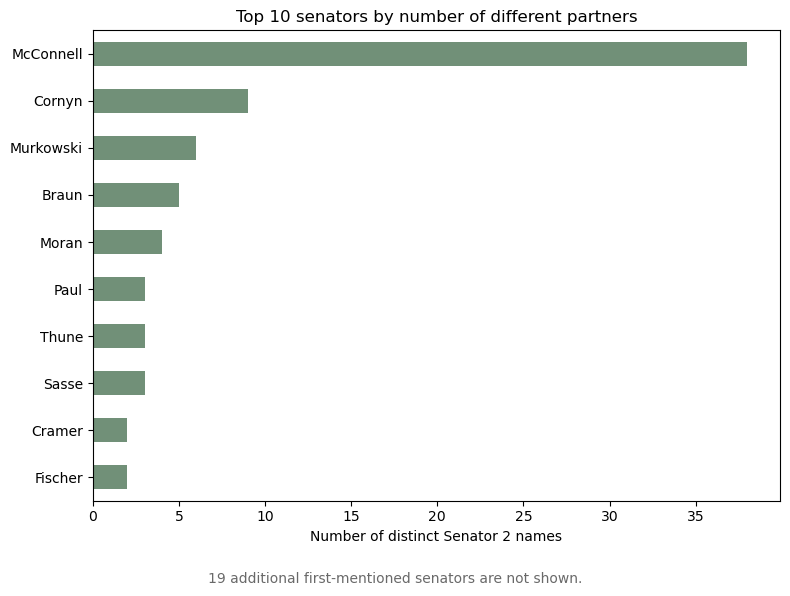

In [20]:
# graph to show the 10 senators with the most different partners
top_10 = coauthors.sort_values("partners", ascending=False).head(10)
remaining = len(coauthors) - len(top_10)

top_10.sort_values("partners").plot.barh(
    x="Senator 1",
    y="partners",
    color="#719078",
    figsize=(8, 6),
    legend=False)

plt.title("Top 10 senators by number of different partners")
plt.xlabel("Number of distinct Senator 2 names")
plt.ylabel("")

# note how many senators aren't displayed
plt.figtext(
    0.5, 0.02,
    f"{remaining} additional first-mentioned senators are not shown.",
    ha="center", fontsize=10, color="dimgray")

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

### Findings

The selected actions are associated with **131 distinct bills**.
Of these, **21 bills** mention one distinct senator and **99 bills**
mention two. The remaining **11 bills** mention three or more senators.
The highest counts are **30** and **38 senators**, showing that a few
bills have selected amendment actions involving many different people.

Using the first two distinct names for each bill, McConnell appears with
the most different second senators wo coauthored the bill with them (**38**), followed by Cornyn (**9**)
and Murkowski (**6**). These results depend on the order in which names
appear in the dataset and do not describe every coauthor relationship.

## New insight: Amendment purpose length vs. senators mentioned

For my additional analysis, I looked at whether amendment descriptions
are longer when more senators are mentioned. I also compared substitute
amendments specifically with other amendments to see whether the pattern changes
between the two groups. (Substitute amendment: proposes replacement text for a bill or another amendment)

I focused on Senate amendments proposed on the floor so that this analysis builds on the senator names extracted in the previous analysis. Also, keeping one action type makes the descriptions more comparable, therefore, these findings apply to this subset, rather than all amendments.

Counting the entire action description can be misleading because
the most descriptions include senator names and Congressional Record
references (in parentheses). So, mentioning another senator would automatically add words and makes the analysis cloudy.
To make the comparison more accurate, I only counted the text describing the amendment's purpose in the action column.

### Process explanation

Most action descriptions place the amendment's purpose after a closing
parenthesis containing Congressional Record references. I split the
text at that parenthesis and kept the remaining description. 

Two records do not have that parenthesis. For those records, I kept
the text after the introductory sentence instead and checked for missing
or empty descriptions after this step for all actions.

I classified amendments containing “In the nature of a substitute”
as substitute amendments. I looked at descriptions containing the word “substitute” and found
the phrase “In the nature of a substitute.” (used this specific phrase
to identify substitute amendments as searching for “substitute”
alone could include other uses of the word unrelated to topic)
All remaining amendments were placed in the
other amendment group. I counted words by splitting the purpose text
at spaces.

In [26]:
# reuse the selected actions and names from the previous section
amendment_lengths = senate_amendments.copy()
amendment_lengths["Senator count"] = amendment_lengths["names"].str.len()

# keep the only purpose (exclude congressional records)
amendment_lengths["Purpose"] = (
    amendment_lengths["action"].str.split(r"\)\s*", n=1).str[1])

# descriptions without a closing parenthesis
missing_purpose = amendment_lengths["Purpose"].isna()
# print("Records without the expected parenthesis:", missing_purpose.sum())

# for those, keep the purpose after the introductory sentence
amendment_lengths.loc[missing_purpose, "Purpose"] = (
    amendment_lengths.loc[missing_purpose, "action"]
    .str.split(". ", regex=False)
    .str[-1])

In [27]:
# remove spaces and count words
amendment_lengths["Purpose"] = amendment_lengths["Purpose"].str.strip()
amendment_lengths["Word count"] = (amendment_lengths["Purpose"]
                                   .str.split().str.len())

print("Missing purposes:", amendment_lengths["Purpose"].isna().sum())
print("Empty purposes:", (amendment_lengths["Purpose"] == "").sum())

Missing purposes: 0
Empty purposes: 0


In [ ]:
# check how the word "substitute" appears in the action text
# examples = amendment_lengths[amendment_lengths["action"].str.contains("substitute", case=False)]

# for text in examples["action"].head(10): 
# print(text)
# print()

In [28]:
# classify amendments using the phrase in their descriptions
amendment_lengths["Amendment type"] = "Other amendment"

is_substitute = amendment_lengths["action"].str.contains("In the nature of a substitute")

amendment_lengths.loc[
    is_substitute, "Amendment type"] = "Substitute amendment"

# Summarize purpose lengths within each group.
length_summary = (amendment_lengths.groupby(["Senator count", "Amendment type"])
    .agg(
        Actions=("Word count", "size"),
        Average_words=("Word count", "mean")))

length_summary.style.format({"Average_words": "{:.2f}"}).set_caption(
    "Amendment purpose length by senator count and type")

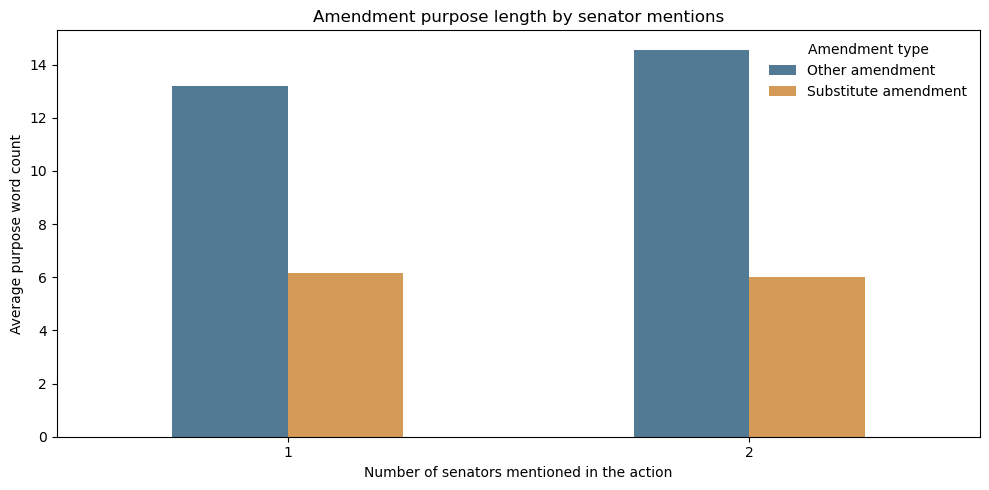

In [31]:
# graph bar plot side by side
graph_data = length_summary["Average_words"].unstack("Amendment type")

graph_data.plot.bar(color=["#527A95", "#D49A58"],figsize=(10, 5),rot=0)

plt.title("Amendment purpose length by senator mentions")
plt.xlabel("Number of senators mentioned in the action")
plt.ylabel("Average purpose word count")
plt.legend(title="Amendment type", frameon=False)
plt.tight_layout()
plt.show()

### Findings

I compared average purpose length within each amendment type. In this
subset, there were only one or two senators mentioned for each action.

For other amendments, purpose descriptions average **13.20 words** when
one senator is mentioned and **14.56 words** when two senators are
mentioned. This suggests that descriptions of purpose of the amendment action with two senators tend to be somewhat
longer within this group.

Substitute amendment descriptions average approximately **6 words**
for both senator counts. I believe this reflects the repeated phrase
“In the nature of a substitute” used rather than a detailed explanation
of the amendment unlike other admendment types.

The amendment type therefore matters when comparing description lengths.
The other amendments show a some difference between senator counts,
while substitute descriptions have the identitcal lengths.

These results do not establish that amendments mentioning two senators
are more complex. The counts reflect the description supplied in the
dataset. The differnce in description length for 1 and 2 numbers of senators mentioned might indicate someone proposing an amendment on behalf of another senator rather than equal involvement in writing it.